# Individual Kelvin-wave sinusoid fits and implied equivalent depths

Fit a single sinusoid jointly in longitude and time for each detected convective
ridge, then plot the distribution of resting-background Kelvin equivalent depths.
This self-contained example uses the same NOAA input, preprocessing, broad filter,
and event definition as `NOAA_OLR_heff_KW_events_radon.ipynb`.

The only dynamical assumption is the resting Kelvin dispersion relation used
**after** estimating wavenumber and frequency. No winds or ERA5 data are required.
Each event contributes one fitted depth to the histogram. All figures stay inline;
no files are written by the notebook.


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.optimize import least_squares
import xr_ccew as tw
from src.paths import DATA_DIR

EARTH_RADIUS_M = 6_371_008.0
GRAVITY_M_S2 = 9.80665
METERS_PER_DEGREE = 2 * np.pi * EARTH_RADIUS_M / 360


## NOAA OLR input and preprocessing

Run in the installed project environment `cmip6_equiv_depth_distributions`, with
NumPy, pandas, xarray, SciPy, Matplotlib, netCDF4, and `xr_ccew` available.
`data/noaa_olr` must be a local symlink to the NOAA archive directory. Data access
uses `DATA_DIR` from the installed package; there are no machine-specific fallback paths.

Read 1991--1994 and examine September 1992--February 1993. Remove three annual
harmonics, remove mean/trend, and apply a Tukey window with total taper fraction
0.1 (5%, or 73 days, per end). The analysis and fitting windows are safely inside
the flat interior. Keep all longitudes for the FFT and average over 20°S--20°N.


In [2]:
OLR_FILE = DATA_DIR / "noaa_olr" / "OLR-Daily_v02r00_s19790101_e20251231.nc"
RECORD_RANGE = ("1991-01-01", "1994-12-31")
ANALYSIS_RANGE = ("1992-09-01", "1993-02-28")
LAT_RANGE = (-20, 20)  # Keep the latitude band used in the original notebook.
TAPER_FRACTION = 0.1
EDGE_BUFFER_DAYS = 120  # Exceeds the 73-day taper at each end of this pilot.

if not OLR_FILE.is_file():
    raise FileNotFoundError(f"Configure data/noaa_olr to expose {OLR_FILE.name}")
with xr.open_dataset(OLR_FILE) as dataset:
    olr = dataset["olr"].sel(
        lat=slice(*LAT_RANGE), time=slice(*RECORD_RANGE)
    ).load()

# Check the actual input, including the noon timestamps of this daily-mean product.
assert olr.attrs["units"] == "W m-2"
assert olr.sizes["lat"] > 0 and np.isfinite(olr.values).all()
assert np.all(np.diff(olr.time.values) == np.timedelta64(1, "D"))
dlon = float(olr.lon.diff("lon")[0])
assert dlon > 0 and np.allclose(np.diff(olr.lon), dlon)
assert np.isclose(olr.sizes["lon"] * dlon, 360)
assert np.allclose(olr.lat.values, -olr.lat.values[::-1])

olr_anom = tw.apply_window(
    tw.remove_mean_and_linear_trend(
        tw.remove_harmonics_of_seasonal_cycle(olr, num_harmonics=3)
    ),
    dim="time", window="tukey", pct=TAPER_FRACTION,
)
print(f"Loaded {dict(olr.sizes)}; units: {olr.attrs['units']}")
print(f"Taper length per end: {TAPER_FRACTION * (olr.sizes['time'] - 1) / 2:.1f} days")


Loaded {'time': 1461, 'lat': 40, 'lon': 360}; units: W m-2
Taper length per end: 73.0 days


## Broad Kelvin filter

Keep global wavenumbers 1--14, periods 2.5--30 days, equivalent-depth curves 1--200 m,
and equatorial symmetry. Use the unweighted latitude mean, as in the other notebooks.
The reference standard deviation uses the untapered interior of the record.


Interior reference standard deviation: 6.46 W m-2


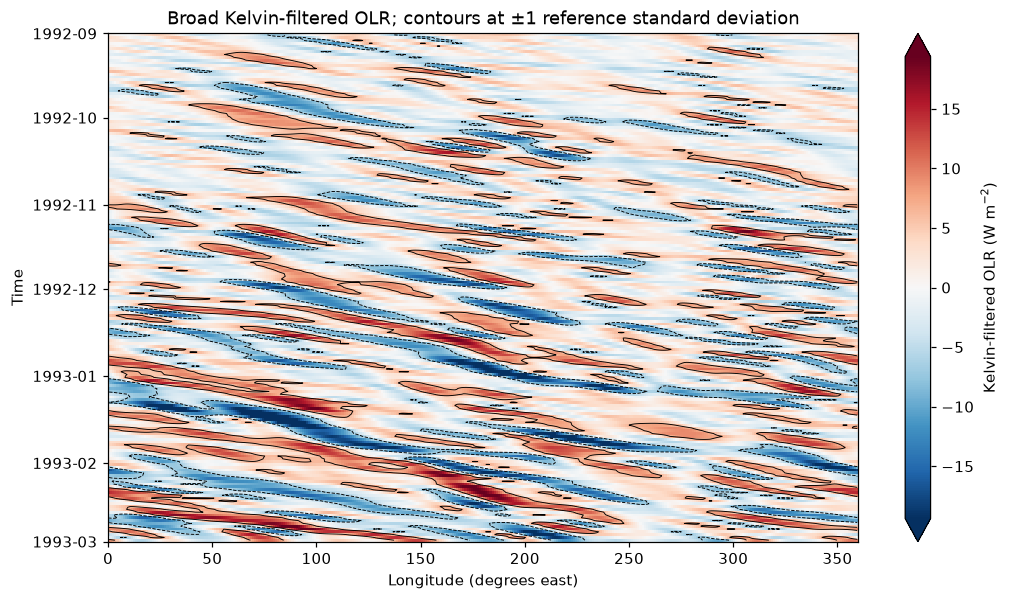

In [3]:
GENERAL_KELVIN = tw.WaveProfile(
    name="KW", aliases=("Kelvin", "Kelvin wave"),
    k_min=1, k_max=14,
    frequency_min=1 / 30, frequency_max=1 / 2.5,
    equivalent_depth_min=1, equivalent_depth_max=200,
    symmetry="symmetric", direction="eastward", curve_name="kelvin",
    description="Broad Kelvin candidate filter for event-scale fitting.",
)
wave_data = tw.filter_field(olr_anom, GENERAL_KELVIN)
hovmoller_wave_data = wave_data.mean("lat").transpose("time", "lon")
reference = hovmoller_wave_data.isel(time=slice(EDGE_BUFFER_DAYS, -EDGE_BUFFER_DAYS))
sigma = float(reference.std())  # Across reference time and all longitudes.
analysis = hovmoller_wave_data.sel(time=slice(*ANALYSIS_RANGE))
assert analysis.time[0] >= reference.time[0] and analysis.time[-1] <= reference.time[-1]

fig, ax = plt.subplots(figsize=(11, 6))
analysis.plot(ax=ax, x="lon", y="time", cmap="RdBu_r", vmin=-3*sigma, vmax=3*sigma,
              cbar_kwargs={"label": "Kelvin-filtered OLR (W m$^{-2}$)"})
analysis.plot.contour(ax=ax, x="lon", y="time", levels=[-sigma, sigma],
                      colors="k", linewidths=0.6)
ax.set(xlabel="Longitude (degrees east)", ylabel="Time",
       title="Broad Kelvin-filtered OLR; contours at ±1 reference standard deviation")
ax.invert_yaxis()
plt.show()
print(f"Interior reference standard deviation: {sigma:.2f} W m-2")


## Discrete event candidates

Use eight-connected negative-OLR ridges below -1 reference standard deviation,
with peak magnitude at least 1.5 standard deviations, duration at least four sampled
days, and longitude span at least 20°. Join across 0/360° and reject events touching
the analysis-time boundaries. This is the same detector as in the Radon example.


In [4]:
DETECTION_SIGMA = 1.0
PEAK_SIGMA = 1.5
MIN_DURATION_DAYS = 4
MIN_LONGITUDE_SPAN_DEG = 20

labels, _ = ndimage.label(
    analysis.values < -DETECTION_SIGMA * sigma,
    structure=np.ones((3, 3), dtype=int),
)
# Same-day and adjacent-day connections across the periodic longitude seam.
for row in range(labels.shape[0]):
    for neighbor in range(max(0, row - 1), min(labels.shape[0], row + 2)):
        left, right = labels[row, 0], labels[neighbor, -1]
        if left and right and left != right:
            labels[labels == max(left, right)] = min(left, right)

rows = []
for component in np.unique(labels[labels > 0]):
    ti, xi = np.where(labels == component)
    peak = np.argmin(analysis.values[ti, xi])
    peak_lon = float(analysis.lon[xi[peak]])
    duration = int(ti.max() - ti.min() + 1)
    event_longitudes = np.unique(analysis.lon.values[xi])
    circular_gaps = np.diff(np.r_[event_longitudes, event_longitudes[0] + 360])
    span = float(360 - circular_gaps.max())
    amplitude = float(-analysis.values[ti[peak], xi[peak]])
    if (ti.min() == 0 or ti.max() == analysis.sizes["time"] - 1
            or duration < MIN_DURATION_DAYS or span < MIN_LONGITUDE_SPAN_DEG
            or amplitude < PEAK_SIGMA * sigma):
        continue
    rows.append(dict(
        event_id=int(component), peak_time=analysis.time.values[ti[peak]],
        peak_lon_deg=peak_lon, duration_days=duration, span_deg=span,
        peak_amplitude_W_m2=amplitude,
    ))

events = pd.DataFrame(rows)
if events.empty:
    raise RuntimeError("No candidates meet the stated thresholds; inspect the Hovmöller.")
events = events.sort_values("peak_time").reset_index(drop=True)
print(f"{len(events)} amplitude-selected candidate ridges")
events


37 amplitude-selected candidate ridges


,event_id,peak_time,peak_lon_deg,duration_days,span_deg,peak_amplitude_W_m2
0,4,1992-09-04 12:00:00,109.5,5,42.0,11.538904
1,16,1992-09-26 12:00:00,88.5,17,95.0,13.126056
2,31,1992-10-03 12:00:00,261.5,5,45.0,11.048784
3,35,1992-10-07 12:00:00,188.5,11,62.0,18.326148
4,41,1992-10-11 12:00:00,168.5,4,29.0,15.127024
5,43,1992-10-20 12:00:00,158.5,10,65.0,10.764333
6,47,1992-10-30 12:00:00,125.5,6,47.0,12.198087
7,51,1992-10-31 12:00:00,176.5,4,38.0,10.951222
8,60,1992-11-07 12:00:00,334.5,9,84.0,13.134418
9,63,1992-11-10 12:00:00,192.5,6,57.0,15.070828


## Joint longitude--time sinusoid fit

Within a local window around the event peak, fit the **signed** field (both
enhanced and suppressed convection):

$$q(\lambda,t)=b+A\cos\theta+B\sin\theta,\qquad
\theta=K(\lambda-\lambda_0)-2\pi f(t-t_0).$$

Longitude is in radians, time in days, $K$ is global zonal wavenumber (cycles per
360°), and $f$ is cycles/day. Gaussian weights emphasize the event's neighborhood.
For every trial $(K,f)$, solve $b,A,B$ by linear least squares. Search a coarse grid
and refine its three best starting points with bounded nonlinear least squares.
The fit searches a rectangle in $(K,f)$; it does not impose a depth curve.

Then $k=K/a$, $\omega=2\pi f/86400$, $c=\omega/k$, and
$h_{\rm eff}^{(U=0)}=c^2/g$. The constant-amplitude sinusoid is a local approximation
to a wave packet; window dependence and overlapping signals can affect the estimates.


In [5]:
def fit_event_sinusoid(field, center_time, center_lon, *, k_grid, frequency_grid,
                       half_window_days, half_width_deg, time_sigma_days, lon_sigma_deg):
    """Fit q=b+A*cos(theta)+B*sin(theta) in a daily (time, lon) field.

    K is cycles/360 degrees; f is cycles/day; field values are W/m2. Return
    event parameters and local diagnostic arrays. Longitude wrapping is periodic.
    """
    center_time = np.datetime64(center_time)
    half_window = np.timedelta64(half_window_days, "D")
    patch = field.sel(time=slice(center_time-half_window, center_time+half_window))
    if patch.sizes["time"] != 2 * half_window_days + 1:
        raise ValueError("The full event fitting window is not available.")
    relative_lon = (patch.lon.values - center_lon + 180) % 360 - 180
    order = np.argsort(relative_lon)
    order = order[np.abs(relative_lon[order]) <= half_width_deg]
    patch = patch.isel(lon=order).assign_coords(lon=relative_lon[order])
    lag_days = (patch.time.values - center_time) / np.timedelta64(1, "D")
    lon_rad, lag = np.meshgrid(np.deg2rad(patch.lon.values), lag_days)
    weights = np.exp(-0.5*(lag/time_sigma_days)**2
                     -0.5*(np.rad2deg(lon_rad)/lon_sigma_deg)**2)
    sqrt_weights = np.sqrt(weights).ravel()
    y = patch.values.ravel()
    weighted_y = sqrt_weights * y
    mean = np.average(y, weights=weights.ravel())
    null_sse = np.sum(weights.ravel() * (y-mean)**2)
    if null_sse <= 0:
        raise ValueError("A constant field cannot identify a wave.")
    time_span_days = float(np.ptp(lag_days))
    # Scale f to cycles per window so both optimized parameters have comparable sizes.
    x = lon_rad.ravel()
    scaled_time = lag.ravel() / time_span_days

    def residuals(parameters):
        K, cycles_per_window = parameters
        phase = K*x - 2*np.pi*cycles_per_window*scaled_time
        design = np.column_stack([np.ones_like(phase), np.cos(phase), np.sin(phase)])
        weighted_design = sqrt_weights[:, None] * design
        coefficients = np.linalg.lstsq(weighted_design, weighted_y, rcond=None)[0]
        return (weighted_design @ coefficients - weighted_y) / np.sqrt(null_sse)

    coarse_pairs = np.array([(K, f*time_span_days) for K in k_grid for f in frequency_grid])
    coarse_sse = np.array([np.sum(residuals(pair)**2) for pair in coarse_pairs])
    lower = [k_grid[0], frequency_grid[0]*time_span_days]
    upper = [k_grid[-1], frequency_grid[-1]*time_span_days]
    solutions = [least_squares(
        residuals, coarse_pairs[index], bounds=(lower, upper),
        ftol=1e-9, xtol=1e-9, gtol=1e-9, max_nfev=200,
    ) for index in np.argsort(coarse_sse)[:3]]
    solution = min(solutions, key=lambda fit: np.sum(fit.fun**2))
    K, cycles_per_window = solution.x
    frequency = cycles_per_window / time_span_days
    phase = K*x - 2*np.pi*cycles_per_window*scaled_time
    design = np.column_stack([np.ones_like(phase), np.cos(phase), np.sin(phase)])
    b, A, B = np.linalg.lstsq(sqrt_weights[:, None]*design, weighted_y, rcond=None)[0]
    model = (design @ np.array([b, A, B])).reshape(patch.shape)
    omega = 2*np.pi*frequency/86400
    k = K / EARTH_RADIUS_M
    speed = omega / k
    at_edge = (np.isclose(solution.x, lower, rtol=0, atol=1e-4).any()
               or np.isclose(solution.x, upper, rtol=0, atol=1e-4).any())
    result = dict(
        K_global=float(K), frequency_cpd=float(frequency), k_rad_m=float(k),
        omega_rad_s=float(omega), phase_speed_m_s=float(speed),
        h_eff_m=float(speed**2/GRAVITY_M_S2), period_days=float(1/frequency),
        amplitude_W_m2=float(np.hypot(A, B)), offset_W_m2=float(b),
        phase_rad=float(np.arctan2(B, A)), weighted_r2=float(1-np.sum(solution.fun**2)),
        spatial_cycles=float(K*np.ptp(patch.lon.values)/360),
        temporal_cycles=float(frequency*time_span_days),
        fit_success=bool(solution.success), at_search_edge=bool(at_edge),
    )
    diagnostic = dict(
        observed=patch, fitted=patch.copy(data=model), weights=weights,
        k_grid=k_grid, frequency_grid=frequency_grid,
        coarse_r2=(1-coarse_sse).reshape(len(k_grid), len(frequency_grid)),
    )
    return result, diagnostic


# Coarse search spacings set starting points, not the final fitted resolution.
FIT_OPTIONS = dict(
    k_grid=np.arange(1.0, 15.0),
    frequency_grid=np.linspace(1/30, 1/2.5, 17),
    half_window_days=10, half_width_deg=90,
    time_sigma_days=5, lon_sigma_deg=45,
)
MIN_WEIGHTED_R2 = 0.3
MIN_SPATIAL_CYCLES = 1.0
MIN_TEMPORAL_CYCLES = 1.0


## Check known wavenumber and frequency

First recover an exact sinusoid, then a localized packet with noise. The packet
is centered near the longitude seam and uses noninteger K. Its noisy fit need not
recover the prescribed values exactly. These checks validate the estimator's sign,
units, wrapping, and basic recovery; they do not calibrate event uncertainties.


In [6]:
known_K = 6.4
known_speed = 15.0
known_frequency = known_speed * known_K * 86400 / (2*np.pi*EARTH_RADIUS_M)
synthetic_center_time = np.datetime64("2000-02-01T12:00:00")
synthetic_lon = np.arange(0.5, 360, 1)
synthetic_days = np.arange(-30, 31)
relative_lon = (synthetic_lon - 359.5 + 180) % 360 - 180
phase = known_K*np.deg2rad(relative_lon)[None, :] - 2*np.pi*known_frequency*synthetic_days[:, None]
synthetic_coords = {
    "time": synthetic_center_time + synthetic_days.astype("timedelta64[D]"),
    "lon": synthetic_lon,
}
exact = xr.DataArray(0.25 - 10*np.cos(phase), dims=("time", "lon"), coords=synthetic_coords)
exact_fit, _ = fit_event_sinusoid(exact, synthetic_center_time, 359.5, **FIT_OPTIONS)
assert abs(exact_fit["K_global"] - known_K) < 1e-3
assert abs(exact_fit["frequency_cpd"] - known_frequency) < 1e-4

moving_lon = 359.5 + known_speed*86400/METERS_PER_DEGREE * synthetic_days[:, None]
distance_deg = (synthetic_lon[None, :] - moving_lon + 180) % 360 - 180
envelope = np.exp(-0.5*(distance_deg/40)**2 - 0.5*(synthetic_days[:, None]/8)**2)
rng = np.random.default_rng(4)
packet = exact.copy(data=0.25 - 10*envelope*np.cos(phase) + rng.normal(0, 0.3, exact.shape))
packet_fit, _ = fit_event_sinusoid(packet, synthetic_center_time, 359.5, **FIT_OPTIONS)
assert abs(packet_fit["K_global"] - known_K) < 0.3
assert abs(packet_fit["frequency_cpd"] - known_frequency) < 0.01
print(f"Prescribed: K={known_K:.3f}, f={known_frequency:.4f} cycles/day, c={known_speed:.2f} m/s")
print(f"Exact fit: K={exact_fit['K_global']:.3f}, f={exact_fit['frequency_cpd']:.4f} cycles/day")
print(f"Noisy packet: K={packet_fit['K_global']:.3f}, f={packet_fit['frequency_cpd']:.4f} cycles/day, "
      f"c={packet_fit['phase_speed_m_s']:.2f} m/s")


Prescribed: K=6.400, f=0.2072 cycles/day, c=15.00 m/s
Exact fit: K=6.400, f=0.2072 cycles/day
Noisy packet: K=6.397, f=0.2072 cycles/day, c=15.01 m/s


## Fit each event and select the histogram sample

Retain all fitted rows, with visible flags. For the demonstration histogram, require
optimizer convergence, an interior optimum, weighted R² ≥ 0.3, and at least one
spatial and temporal cycle across the full fitting window. These are descriptive
fit screens, not statistical-significance tests or confidence intervals.

No extra depth cutoff is applied after fitting. Window and fit-screen choices
define the displayed sample and should be held fixed for model comparisons.


In [7]:
fit_rows, diagnostics = [], {}
for event in events.itertuples(index=False):
    fit, diagnostic = fit_event_sinusoid(
        hovmoller_wave_data, event.peak_time, event.peak_lon_deg, **FIT_OPTIONS
    )
    fit_rows.append(fit)
    diagnostics[event.event_id] = diagnostic

event_fits = pd.concat([events, pd.DataFrame(fit_rows)], axis=1)
event_fits["keep_for_histogram"] = (
    event_fits.fit_success & ~event_fits.at_search_edge
    & (event_fits.weighted_r2 >= MIN_WEIGHTED_R2)
    & (event_fits.spatial_cycles >= MIN_SPATIAL_CYCLES)
    & (event_fits.temporal_cycles >= MIN_TEMPORAL_CYCLES)
)
accepted = event_fits.loc[event_fits.keep_for_histogram].copy()
if accepted.empty:
    raise RuntimeError("No events pass the stated fit screens; inspect event_fits.")
print(f"{len(accepted)} of {len(event_fits)} candidate ridges retained for the histogram")
event_fits[["event_id", "peak_time", "peak_lon_deg", "K_global", "frequency_cpd",
            "phase_speed_m_s", "h_eff_m", "weighted_r2", "keep_for_histogram"]]


10 of 37 candidate ridges retained for the histogram


,event_id,peak_time,peak_lon_deg,K_global,frequency_cpd,phase_speed_m_s,h_eff_m,weighted_r2,keep_for_histogram
0,4,1992-09-04 12:00:00,109.5,4.211215,0.091074,10.019831,10.237647,0.227263,False
1,16,1992-09-26 12:00:00,88.5,3.889823,0.063053,7.510122,5.751397,0.526588,True
2,31,1992-10-03 12:00:00,261.5,2.841247,0.078615,12.819483,16.757928,0.289380,False
3,35,1992-10-07 12:00:00,188.5,3.209438,0.060096,8.675419,7.674680,0.288977,False
4,41,1992-10-11 12:00:00,168.5,2.858168,0.056673,9.186788,8.606107,0.260735,False
5,43,1992-10-20 12:00:00,158.5,7.660518,0.115100,6.961300,4.941513,0.235786,False
6,47,1992-10-30 12:00:00,125.5,3.091703,0.066789,10.008802,10.215122,0.329951,True
7,51,1992-10-31 12:00:00,176.5,6.348799,0.228662,16.686950,28.394437,0.158194,False
8,60,1992-11-07 12:00:00,334.5,3.729492,0.049712,6.175669,3.889084,0.220559,False
9,63,1992-11-10 12:00:00,192.5,5.924586,0.155490,12.159618,15.077146,0.175040,False


## Inspect one local fit

Show the retained event with the largest weighted R². Color is the observed signed
field; black contours show the fitted sinusoid at its offset ± half amplitude.
The separate coarse-search surface shows possible competing fits. Its width is
not a confidence interval, and its grid does not set the final fit resolution.


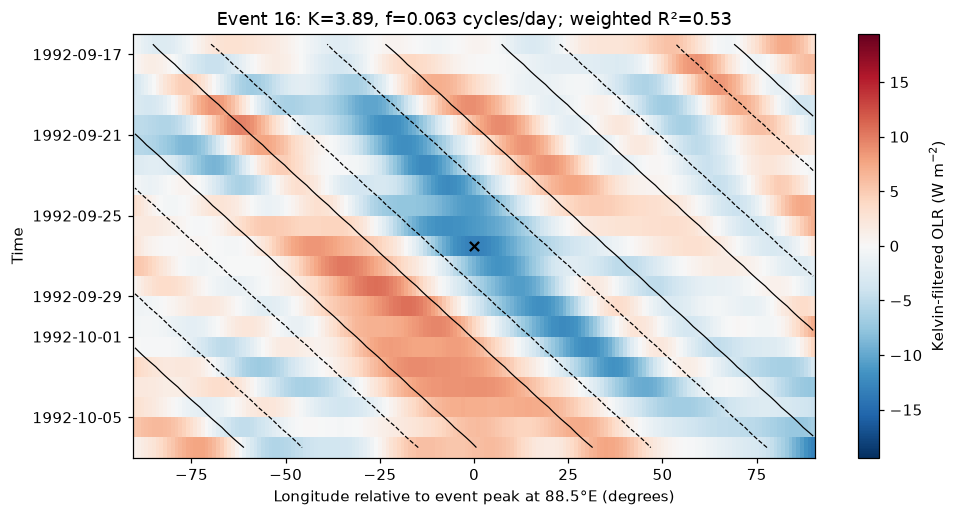

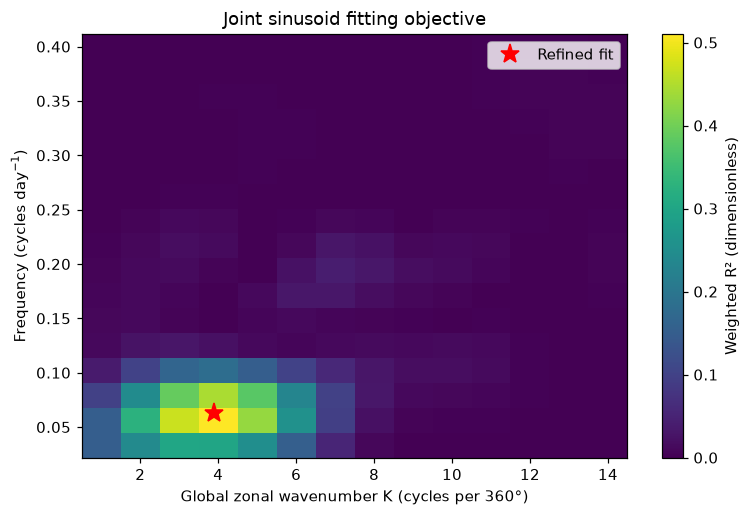

In [8]:
chosen = accepted.sort_values("weighted_r2", ascending=False).iloc[0]
diagnostic = diagnostics[int(chosen.event_id)]
fig, ax = plt.subplots(figsize=(10, 5))
diagnostic["observed"].plot(
    ax=ax, x="lon", y="time", cmap="RdBu_r", vmin=-3*sigma, vmax=3*sigma,
    cbar_kwargs={"label": "Kelvin-filtered OLR (W m$^{-2}$)"},
)
diagnostic["fitted"].plot.contour(
    ax=ax, x="lon", y="time", colors="k", linewidths=0.8,
    levels=[chosen.offset_W_m2-0.5*chosen.amplitude_W_m2,
            chosen.offset_W_m2+0.5*chosen.amplitude_W_m2],
)
ax.scatter([0], [chosen.peak_time], color="k", marker="x", zorder=5)
ax.set(xlabel=f"Longitude relative to event peak at {chosen.peak_lon_deg:.1f}°E (degrees)",
       ylabel="Time", title=(f"Event {int(chosen.event_id)}: K={chosen.K_global:.2f}, "
       f"f={chosen.frequency_cpd:.3f} cycles/day; weighted R²={chosen.weighted_r2:.2f}"))
ax.invert_yaxis()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
mesh = ax.pcolormesh(
    diagnostic["k_grid"], diagnostic["frequency_grid"], diagnostic["coarse_r2"].T,
    shading="auto", cmap="viridis", vmin=0,
)
ax.plot(chosen.K_global, chosen.frequency_cpd, "r*", markersize=13, label="Refined fit")
ax.set(xlabel="Global zonal wavenumber K (cycles per 360°)",
       ylabel="Frequency (cycles day$^{-1}$)", title="Joint sinusoid fitting objective")
fig.colorbar(mesh, ax=ax, label="Weighted R² (dimensionless)")
ax.legend()
plt.show()


## Distribution of implied Kelvin equivalent depths

Plot an equal-event-weight histogram of $h_{\rm eff}^{(U=0)}=(\omega/k)^2/g$ for the
retained fits. Use 10 m bins starting at zero and extend the axis to include every
retained depth. Density is normalized so the sum of density × bin width is one.
The table gives descriptive sample statistics; the median line is not an uncertainty estimate.


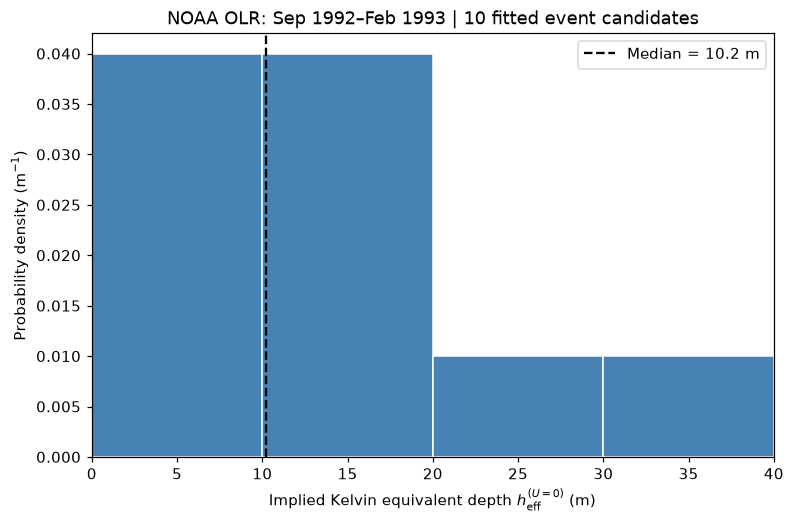

,Implied depth (m)
count,10.000000
mean,13.527095
std,11.169819
min,4.073942
25%,7.434306
50%,10.235364
75%,11.460677
max,39.070059


In [9]:
BIN_WIDTH_M = 10.0
depths = accepted["h_eff_m"].to_numpy()
upper_edge = max(BIN_WIDTH_M, BIN_WIDTH_M * np.ceil(depths.max()/BIN_WIDTH_M))
bin_edges = np.arange(0, upper_edge + BIN_WIDTH_M, BIN_WIDTH_M)
density, edges = np.histogram(depths, bins=bin_edges, density=True)
assert np.isclose(np.sum(density * np.diff(edges)), 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(depths, bins=bin_edges, density=True, color="steelblue", edgecolor="white")
ax.axvline(np.median(depths), color="k", linestyle="--",
           label=f"Median = {np.median(depths):.1f} m")
ax.set(xlabel=r"Implied Kelvin equivalent depth $h_{\mathrm{eff}}^{(U=0)}$ (m)",
       ylabel=r"Probability density (m$^{-1}$)",
       title=f"NOAA OLR: Sep 1992–Feb 1993 | {len(depths)} fitted event candidates",
       xlim=(0, upper_edge))
ax.legend()
plt.show()
accepted["h_eff_m"].describe().rename("Implied depth (m)").to_frame()


## Interpretation

This is a small-sample distribution of propagation-inferred depths under U=0,
conditional on the broad Kelvin filter, amplitude-based event selection, local
single-sinusoid approximation, and stated fit screens. Neighboring ridges can be
related, and fit errors broaden the distribution. It is a first OLR-only diagnostic;
it does not attribute model differences to a particular physical mechanism.

For a model comparison, use identical processing and test sensitivity to fitting
windows and selection. ER and other wave families require their own dispersion
relation when converting fitted k and omega to depth.
